In [1]:

from torch.utils.data import DataLoader

from forklens import train
from forklens.dataset import ShapeDataset, CaliDataset

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

dir = '/home/z/Zekang.Zhang/forklens/'

from forklens.config_loader import Config
config = Config(dir + "examples/cnn/config.yaml")

In [2]:
# Load data catalog

with fits.open(dir+'/data/csst_catalog_example.fits') as f:
    cat = f[0].data
cut_idx = np.where((cat[:,0]>0.1)&(cat[:,1]<25))[0]
size_cat = cat[cut_idx,0]
mag_cat = cat[cut_idx,1]

## CNN

In [4]:
# Generate data
def dataframe(num, seed=12345):
    
    num = int(num/2)
    
    rng1 = np.random.RandomState(seed)
    idx = rng1.randint(0,mag_cat.shape[0],size=num)
    Gal_Hlr   = size_cat[idx]
    Gal_Hlr   = np.concatenate((Gal_Hlr, Gal_Hlr), axis=0)
    Gal_Mag   = mag_cat[idx]
    Gal_Mag   = np.concatenate((Gal_Mag, Gal_Mag), axis=0)
    
    rng2 = np.random.RandomState(seed+1)
    Gal_Theta = rng2.random(num*2)*2*np.pi
    Gal_ELL = np.sqrt(rng2.random(num*2))*0.999
    e1 = Gal_ELL*np.sin(2*Gal_Theta)
    e2 = Gal_ELL*np.cos(2*Gal_Theta)

    rng3 = np.random.RandomState(seed+2)
    # PSF_randint = rng3.randint(0,10000,size=num)
    # PSF_randint = np.concatenate((PSF_randint, PSF_randint), axis=0)

    # PSF_fwhm = rng3.random(num)*0.2+0.2
    # PSF_fwhm = np.concatenate((PSF_fwhm, PSF_fwhm), axis=0)
    # PSF_shear = rng3.random((num,2))*0.1-0.05
    # PSF_shear = np.concatenate((PSF_shear, PSF_shear), axis=0)
    # PSF_beta = np.ones(num*2)*2.4

    PSF_fwhm = np.ones(num*2)*0.4
    PSF_shear = np.zeros((num*2,2))
    PSF_beta = np.ones(num*2)*2.4
    
    gal_pars = {}
    gal_pars["e1"] = e1
    gal_pars["e2"] = e2
    gal_pars["hlr_disk"] = Gal_Hlr
    gal_pars["mag_i"] = Gal_Mag
    
    psf_pars = {}
    # psf_pars['randint'] = PSF_randint
    psf_pars['fwhm'] = PSF_fwhm
    psf_pars['e1'] = PSF_shear[:,0]
    psf_pars['e2'] = PSF_shear[:,1]
    psf_pars['beta'] = PSF_beta
    
    return gal_pars, psf_pars

In the above we generate a input catalog of the training dataset (including both training and validation).

Note two catalogs are generated: one for galaxies and one for PSFs. The catalog for PSFs is simply random index which does not make a difference here, as the simulated PSF image in this code is unchanged for simplicity. 

One may want to rewrite his own code for simulation.py and also to customize dataset.py.  

In [5]:
# Get data loader
nSims = 50000
GalCat, PSFCat = dataframe(nSims, seed=12345)
train_ds = ShapeDataset(GalCat, PSFCat, config)

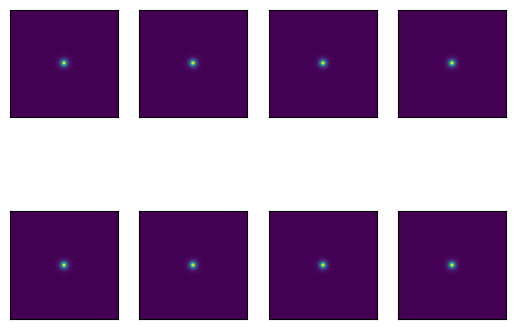

In [23]:

for i,ii in enumerate(np.random.randint(nSims,size=8)):
    item = train_ds.__getitem__(ii)

    plt.subplot(2,4,i+1)
    plt.imshow(item['psf_image'][0]);
    plt.xticks([])
    plt.yticks([])

Some hyper parameters for training are to be modified in ./config.py.

In [ ]:
# Train the network
tr = train.Train(config)
loss = tr.run(train_ds, show_log=True);

Train_dl: 180 Validation_dl: 20
Begin training ...
[TRAIN] Epoch: 1 Loss: 0.31865889027844624 Time: 0:21
[VALID] Epoch: 1 Loss: 0.3952853106771844 Time: 0:3
[TRAIN] Epoch: 2 Loss: 0.25521458189152674 Time: 0:17
[VALID] Epoch: 2 Loss: 0.30684498822748807 Time: 0:2
[TRAIN] Epoch: 3 Loss: 0.2459214202126566 Time: 0:17
[VALID] Epoch: 3 Loss: 0.3548926899511096 Time: 0:2
[TRAIN] Epoch: 4 Loss: 0.24137922972164105 Time: 0:16
[VALID] Epoch: 4 Loss: 0.28413008030772974 Time: 0:2
[TRAIN] Epoch: 5 Loss: 0.2399545469469282 Time: 0:17
[VALID] Epoch: 5 Loss: 0.26166217569686817 Time: 0:2
[TRAIN] Epoch: 6 Loss: 0.23850174722373338 Time: 0:17
[VALID] Epoch: 6 Loss: 0.2603167896272222 Time: 0:2
[TRAIN] Epoch: 7 Loss: 0.2365749846692462 Time: 0:16
[VALID] Epoch: 7 Loss: 0.2820155526386772 Time: 0:2
[TRAIN] Epoch: 8 Loss: 0.23461550585061197 Time: 0:16
[VALID] Epoch: 8 Loss: 0.2607076604178274 Time: 0:2
[TRAIN] Epoch: 9 Loss: 0.2346130025825751 Time: 0:16
[VALID] Epoch: 9 Loss: 0.2718848471940972 Time: 

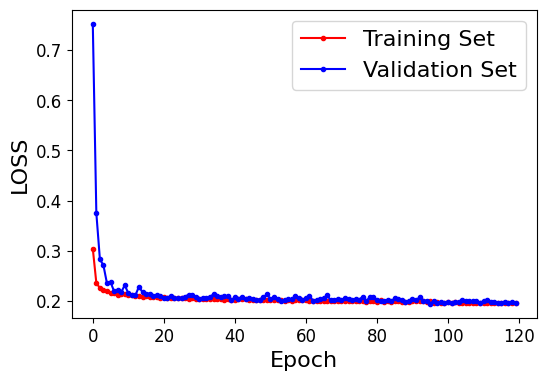

In [ ]:
plt.figure(figsize=(6,4))

plt.plot(loss[0], 'r.-', label="Training Set")
plt.plot(loss[1], 'b.-', label='Validation Set')

plt.xlabel("Epoch", fontsize=16)
plt.ylabel("LOSS", fontsize=16)
plt.tick_params(axis='both',which='major',labelsize=12)
plt.legend(fontsize=16)

## Calibration

In [3]:
import pickle

In [4]:
def dataframe_cali(case_num, real_num, seed=42):

    rng = np.random.RandomState(seed)
    Gal_Shear   = rng.random((case_num,2))*(-0.1-0.1)+0.1

    rng1 = np.random.RandomState(seed + 1)
    idx = rng1.randint(0,mag_cat.shape[0],size=(case_num,1))
    Gal_Hlr     = size_cat[idx]
    Gal_Mag     = mag_cat[idx]
    Gal_Hlr     = np.repeat(Gal_Hlr, real_num, axis=1)
    Gal_Mag     = np.repeat(Gal_Mag, real_num, axis=1)

    rng2 = np.random.RandomState(seed + 2)
    Gal_AxRatio = rng1.random(size=(case_num,1))*(0.1-1)+1

    Gal_Phi     = np.linspace(-np.pi/2,np.pi/2,int(real_num/2))
    Gal_Phi     = np.concatenate((Gal_Phi, Gal_Phi+np.pi/2),axis=0)

    Gal_E1 = (1-Gal_AxRatio)/(1+Gal_AxRatio)*np.cos(Gal_Phi*2)
    Gal_E2 = (1-Gal_AxRatio)/(1+Gal_AxRatio)*np.sin(Gal_Phi*2)

    gal_pars = {}
    gal_pars["e1"] = Gal_E1
    gal_pars["e2"] = Gal_E2
    gal_pars["hlr_disk"] = Gal_Hlr
    gal_pars["mag_i"] = Gal_Mag
    # gal_pars['randint'] = PSF_randint

    shear_pars = {}
    shear_pars['shear'] = Gal_Shear

    # rng3 = np.random.RandomState(seed + 3)
    # PSF_randint = rng.randint(0,high=10000,size=(case_num,1))
    PSF_fwhm = np.ones((case_num,real_num))*0.3
    PSF_shear = np.zeros((case_num,real_num,2))
    PSF_beta = np.ones((case_num,real_num))*2.4
    
    psf_pars = {}
    # psf_pars['randint'] = PSF_randint
    psf_pars['fwhm'] = PSF_fwhm
    psf_pars['e1'] = PSF_shear[:,:,0]
    psf_pars['e2'] = PSF_shear[:,:,1]
    psf_pars['beta'] = PSF_beta

    return gal_pars, psf_pars, shear_pars

In [5]:
case_num = 2000
real_num = 5000

In [ ]:
chunk_size = 200

# ----- 1. Generate the full catalogs once -----
gal_pars_full, psf_pars_full, shear_pars_full = dataframe_cali(
    case_num,
    real_num,
    seed=42,
)

tr = train.Train(config)
model = tr.load_model(
    path=config.train.model_path + "/test_model79",
    strict=True
)

all_results = []

# ----- 2. Chunk through the FIRST axis only -----
for start in range(0, case_num, chunk_size):
    end = min(start + chunk_size, case_num)

    # ----- 3. Slice each catalog -----
    gal_pars = {
        k: v[start:end]            # shape (chunk_size, real_num or ..)
        for k, v in gal_pars_full.items()
    }
    psf_pars = {
        k: v[start:end]
        for k, v in psf_pars_full.items()
    }
    shear_pars = {
        k: v[start:end]
        for k, v in shear_pars_full.items()
    }

    # ----- 4. Build dataset + dataloader for the chunk -----
    cali_ds = CaliDataset(shear_pars, gal_pars, psf_pars, config)
    cali_dl = DataLoader(
        cali_ds,
        batch_size=config.nntrain.batch_size,
        num_workers=config.nntrain.workers
    )

    # ----- 5. Predict on chunk -----
    res_chunk = tr.predict(cali_dl, model)
    all_results.append(res_chunk)

res = {
    k: np.concatenate(
        [np.atleast_1d(chunk[k]) for chunk in all_results],
        axis=0
    )
    for k in all_results[0].keys()
}

save = True
if save:
    cat_path = '/project/ls-gruen/users/zekang.zhang/cats/TypeI_5000case_2000real.pkl'

    with open(cat_path, 'wb') as f:
        pickle.dump(res, f)

In [25]:
def organize_result(res, case_num, real_num):

    dataset = np.zeros((case_num*real_num,12))
    dataset[:,0] = res['ids']
    dataset[:,1:5] = res['preds']
    dataset[:,5:9] = res['targets']
    dataset[:,9:12] = res['info']

    inputs = dataset.reshape(case_num,real_num,12)
    # print(f'inputs shape: {inputs.shape}')

    labels = np.median(inputs[:,:,10:12],axis=1)
    print(f'labels shape: {labels.shape}')

    mean_feature = np.mean(inputs[:,:,1:5],axis=1)
    print(f'mean_feature shape: {mean_feature.shape}')

    mean_snr = np.mean(inputs[:,:,9],axis=1)
    # mean_snr[mean_snr>20] = 20
    mean_snr = np.log10(mean_snr)
    print(f'mean_snr shape: {mean_snr.shape}')

    return mean_feature, mean_snr, labels

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

def create_and_split_data(x, c, y, test_size=0.2, random_state=42):
    """Creates the DataFrame, defines features/target, and splits the data."""
    print("--- 1. Creating and Splitting Data ---")
    data = pd.DataFrame({'x': x, 'c': c, 'y': y})
    
    X = data[['x', 'c']] 
    y = data['y']
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    return X_train, X_test, y_train, y_test

def scale_data(X_train, X_test):
    """Fits a StandardScaler and transforms both datasets."""
    print("--- 2. Scaling Data ---")
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return scaler, X_train_scaled, X_test_scaled

def train_rf_regressor(X_train_scaled, y_train, **kwargs):
    """Initializes and trains the Random Forest Regressor."""
    print("--- 3. Training Random Forest Regressor ---")
    params = {
        'n_estimators': 500,        
        'min_samples_leaf': 10,     
        'random_state': 42,         
        'n_jobs': -1,
    }
    params.update(kwargs) 

    rf = RandomForestRegressor(**params)
    rf.fit(X_train_scaled, y_train)
    print("Training complete.")
    return rf

def predict_quantiles_optimized(model, X_train_scaled, X_test_scaled, y_train, quantiles):
    """
    Optimized custom function to predict quantiles (QRF-style) 
    by leveraging the full conditional distribution in the leaf nodes.
    """
    print("--- 4. Calculating Optimized Quantile Predictions ---")
    
    # Crucial Optimization: Calculate leaf IDs for training and test sets once.
    train_leaf_ids = model.apply(X_train_scaled) # Shape (n_train, n_estimators)
    test_leaf_ids = model.apply(X_test_scaled)   # Shape (n_test, n_estimators)
    
    predictions = np.zeros((X_test_scaled.shape[0], len(quantiles)))
    y_train_arr = y_train # Use numpy array for efficient indexing
    
    # Iterate through each test point
    for i in range(X_test_scaled.shape[0]):
        train_samples_in_leaves = []
        
        # Iterate through each tree (j) in the forest
        for j in range(model.n_estimators):
            
            # Find the leaf index for the i-th test point in the j-th tree
            leaf_idx_test = test_leaf_ids[i, j]
            
            # Find the indices of ALL training samples that fell into this specific leaf
            # This is an efficient numpy comparison
            is_in_leaf = (train_leaf_ids[:, j] == leaf_idx_test)
            
            # Collect the target values of those training samples (the "neighbors")
            train_samples_in_leaves.extend(y_train_arr[is_in_leaf])
        
        # Calculate the desired quantiles from the collected samples
        if train_samples_in_leaves:
            predictions[i, :] = np.quantile(train_samples_in_leaves, quantiles)
        else:
            predictions[i, :] = np.nan

    return predictions

def visualize_results(X_test_original, y_true, y_median, y_lower, y_upper):
    """
    Generates a scatter plot of true values vs. predicted median, 
    with the prediction interval shaded.
    """
    print("--- 5. Visualizing Results ---")
    
    # Create a DataFrame for easy plotting and sorting
    plot_data = pd.DataFrame({
        'x': X_test_original[:, 0],
        'SNR': X_test_original[:, 1],
        'y_true': y_true,
        'y_median': y_median,
        'y_lower': y_lower,
        'y_upper': y_upper,
    }).sort_values(by='x') 

    plt.figure(figsize=(10, 6))

    # Scatter plot of actual data, colored by SNR
    scatter = plt.scatter(plot_data['x'], plot_data['y_true'], 
                          c=plot_data['SNR'], s=15, cmap='viridis', 
                          label='Actual Data (Color=SNR)', alpha=0.6)

    # Plot the uncertainty band (90% interval)
    plt.fill_between(plot_data['x'], plot_data['y_lower'], plot_data['y_upper'],
                     color='red', alpha=0.15, label='90% Prediction Interval')

    # Plot the predicted median line
    plt.plot(plot_data['x'], plot_data['y_median'], color='red', linewidth=1.5, 
             linestyle='--', label='RF Median Prediction')

    plt.title('Quantile Regression Forest (QRF) Style Prediction Intervals')
    plt.xlabel('x (Primary Feature)')
    plt.ylabel('y (Target)')
    cbar = plt.colorbar(scatter)
    cbar.set_label('SNR (Conditional Feature)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [10]:
cat_path = '/project/ls-gruen/users/zekang.zhang/cats/TypeI_5000case_2000real.pkl'
with open(cat_path, 'rb') as f:
    res = pickle.load(f)
mean_feature, mean_snr, labels = organize_result(res, case_num, real_num)

NameError: name 'shear_pars_full' is not defined

--- 1. Creating and Splitting Data ---
--- 2. Scaling Data ---
--- 3. Training Random Forest Regressor ---
Training complete.
--- 4. Calculating Optimized Quantile Predictions ---
--- 5. Visualizing Results ---


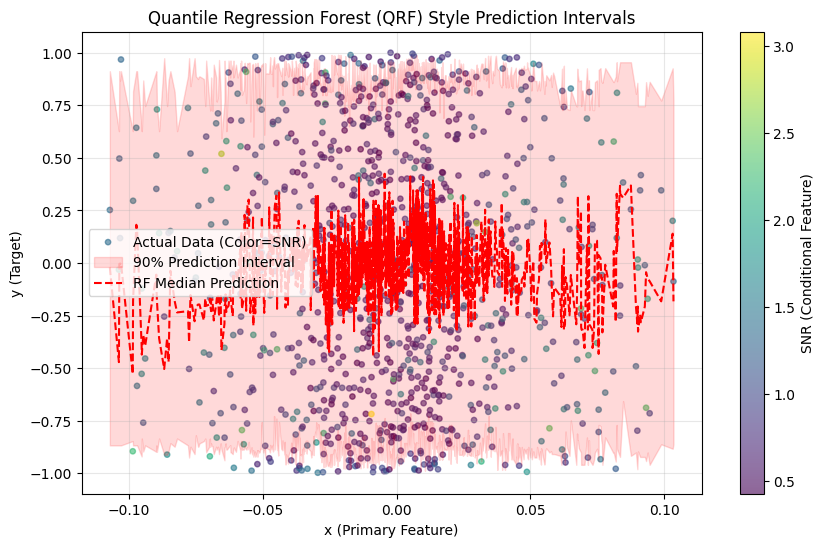

In [108]:
data = {'x':mean_feature[0,:],'c':mean_snr,'y':labels[0,:]}

X_train, X_test, y_train, y_test = create_and_split_data(data['x'], data['c'], data['y'])
scaler, X_train_scaled, X_test_scaled = scale_data(X_train, X_test)

rf_model = train_rf_regressor(X_train_scaled, y_train.values)

quantiles=[0.05, 0.5, 0.95]
y_pred_quantiles = predict_quantiles_optimized(
    rf_model, X_train_scaled, X_test_scaled, y_train.values, quantiles
)

median_index = quantiles.index(0.5)
lower_index = quantiles.index(min(q for q in quantiles if q < 0.5))
upper_index = quantiles.index(max(q for q in quantiles if q > 0.5))

y_pred_median = y_pred_quantiles[:, median_index]
y_pred_lower = y_pred_quantiles[:, lower_index]
y_pred_upper = y_pred_quantiles[:, upper_index]

X_test_original = scaler.inverse_transform(X_test_scaled)

visualize_results(X_test_original, y_test.values, y_pred_median, y_pred_lower, y_pred_upper)

In [101]:
def infer_shear_bias(snr_values, rf_mean, scaler):
    """
    Infers the estimated gain m_hat(SNR) and offset c_hat(SNR) 
    from the trained DRF mean predictor.
    """
    
    # Input set for c_hat (y_true = 0)
    X_c = pd.DataFrame({'x': np.zeros_like(snr_values), 'c': snr_values})
    
    # Input set for m_hat + c_hat (y_true = 1)
    X_m_plus_c = pd.DataFrame({'x': np.ones_like(snr_values), 'c': snr_values})
    
    # Scale inputs
    X_c_scaled = scaler.transform(X_c)
    X_m_plus_c_scaled = scaler.transform(X_m_plus_c)

    # Predict the offset: c_hat(SNR) = mu_hat(y=0, SNR)
    c_hat = rf_mean.predict(X_c_scaled)
    
    # Predict the sum: mu_hat(y=1, SNR) = m_hat + c_hat
    m_plus_c_hat = rf_mean.predict(X_m_plus_c_scaled)
    
    # Calculate the gain: m_hat(SNR) = [m + c] - c
    m_hat = m_plus_c_hat - c_hat
    
    return m_hat, c_hat


test_snrs = np.array([0.15, 0.5, 0.9])
m_est, c_est = infer_shear_bias(test_snrs, rf_model, scaler)

In [102]:
m_est

array([0.73589702, 0.7428699 , 0.90153672])